# Introduction to AI — Beginner Examples

**Notebook status:** execution below is saved from a local run. Python 3.13.14; deterministic, synthetic examples; no API credentials or external services.

## Section A — Introduction

Compare an explicit threshold rule with a tiny model whose class means are computed from examples.

**Prerequisites:** Python 3.11+, basic values and function calls. Install notebook support with `python -m pip install -e ".[notebooks]"`. **Objectives:** trace the code, explain its output, identify limitations, and suggest a real-world safety boundary. Full theory: [lesson notes](../lessons/01_introduction_to_artificial_intelligence.md).

In [1]:
import sys
import matplotlib

print(f"Python {sys.version.split()[0]} | matplotlib {matplotlib.__version__}")

Python 3.13.14 | matplotlib 3.10.8


This environment cell records the actual interpreter and plotting-library versions used for this notebook execution. Minimum compatible dependency versions are documented in the course `pyproject.toml`.

## Section B — Beginner explanation

A rule is an instruction a programmer writes. A model is a rule or learned representation that maps inputs to outputs. Inference means applying it to a new input.

The code cells are runnable Python. Explanations before and after each cell distinguish the expected behavior from the actual output saved by this execution.

## Section C — First Python example

Read the inputs and operations before running. The output below is captured from actual execution.

In [2]:
def needs_review(measurement: float, threshold: float = 75.0) -> bool:
    if threshold < 0:
        raise ValueError("threshold must be non-negative")
    return measurement >= threshold

sample = 80.0
print(f"measurement={sample:.1f}; needs_review={needs_review(sample)}")

measurement=80.0; needs_review=True


**Line-by-line walkthrough:** The function accepts a measurement and default threshold. Type hints describe input and output. The guard rejects invalid settings; `>=` includes the boundary; the call supplies 80 and prints the Boolean.

The output immediately above is actual saved execution output. It occurs because the code uses the displayed deterministic input.

## Section D — Intermediate examples

This example adds a more realistic data structure or evaluation step. Inputs are documented in the code.

In [3]:
from collections import defaultdict
training = [(10.0, "normal"), (12.0, "normal"), (80.0, "review"), (90.0, "review")]
sums, counts = defaultdict(float), defaultdict(int)
for value, label in training:
    sums[label] += value
    counts[label] += 1
centers = {label: sums[label] / counts[label] for label in sums}
query = 70.0
predicted = min(centers, key=lambda label: abs(query - centers[label]))
print("class means:", dict(centers))
print("prediction:", predicted)

class means: {'normal': 11.0, 'review': 85.0}
prediction: review


This cell's output is the result of the displayed computation. New Python operations are explained in the code and can be inspected interactively.

## Section E — Advanced examples

This example adds an edge case, metric, or validation concern. Consider both computational behavior and decision consequences.

In [4]:
distances = {label: abs(query - center) for label, center in centers.items()}
minimum = min(distances.values())
winners = [label for label, distance in distances.items() if distance == minimum]
prediction = winners[0] if len(winners) == 1 else "uncertain"
print("distances:", distances, "=>", prediction)

distances: {'normal': 59.0, 'review': 15.0} => review


Interpret each result in the context of the toy data; do not generalize the score to real deployments.

## Section F — Real-world applications

Example application: synthetic network engineering telemetry and read-only triage. The same principles apply to AI, data science, cloud monitoring, automation, and production software.

In [5]:
synthetic_latency_ms = [12, 15, 14, 120, 13]
review = [i for i, value in enumerate(synthetic_latency_ms) if value >= 80]
print("synthetic review-window indices:", review)
print("No network device is contacted or changed.")

synthetic review-window indices: [3]
No network device is contacted or changed.


No live network is contacted. Any production system needs data provenance, permissions, observability, human review, and a rollback/disable plan.

## Section G — Visualization

The chart below is rendered and embedded in this notebook's saved outputs. It uses the small synthetic demonstration data.

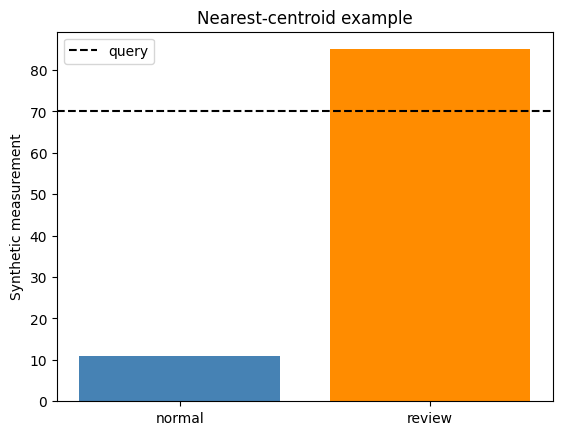

In [6]:
import matplotlib.pyplot as plt
plt.bar(list(centers), list(centers.values()), color=["steelblue", "darkorange"])
plt.axhline(query, color="black", linestyle="--", label="query")
plt.ylabel("Synthetic measurement")
plt.title("Nearest-centroid example")
plt.legend()
plt.show()

The figure supports visual intuition only; it is not validation evidence.

## Section H — Debugging and common mistakes

The following code intentionally reaches an invalid-input path but catches the exception, leaving an inspectable message rather than an unhandled notebook error.

In [7]:
try:
    needs_review(80, threshold=-1)
except ValueError as error:
    print(f"Handled invalid input: {error}")
print("Corrected:", needs_review(80, threshold=75))

Handled invalid input: threshold must be non-negative
Corrected: True


Reject malformed input explicitly; never substitute a success-shaped prediction or silently perform an operational action.

## Section I — Exercises

1. Predict the threshold boundary before running. 2. Add an example and recompute its class mean. 3. Explain why a synthetic latency alert is not fault diagnosis.

Attempt these before using the separate `07_Exercise_Solutions.ipynb`.

## Section J — Summary and knowledge check

A rule is explicit; centroids are computed from labeled examples. Both demonstrations use synthetic data. State one limitation of each approach.

**Review:** What are the input, output, assumptions, failure mode, and safe fallback? Continue with the full theory notes and then AI problem formulation: goals, state, actions, constraints, costs, and success criteria.